In [1]:
# =====================================================
# APPLICATION 3: TIME FORMAT VALIDATION SYSTEM
# FINITE AUTOMATA IMPLEMENTATION
# =====================================================

# STEP 1: Define DFA components

# Input Alphabet
digits = "0123456789"
alphabet = digits + ":"

# Set of States
states = [
    'q0', 'q1', 'q2', 'q3',
    'q4', 'q5', 'q6', 'qd'
]

# Initial State
initial_state = 'q0'

# Final State
final_states = ['q6']


# STEP 2: Define the Transition Function

def transition(state, symbol):

    if state == 'qd':
        return 'qd'

    # First hour digit: 0, 1 or 2
    if state == 'q0':
        if symbol in '01':
            return 'q1'
        elif symbol == '2':
            return 'q2'
        else:
            return 'qd'

    # Second hour digit for 00-19
    if state == 'q1':
        if symbol in digits:
            return 'q3'
        return 'qd'

    # Second hour digit for 20-23
    if state == 'q2':
        if symbol in '0123':
            return 'q3'
        return 'qd'

    # Colon separator
    if state == 'q3':
        if symbol == ':':
            return 'q4'
        return 'qd'

    # First minute digit: 0-5
    if state == 'q4':
        if symbol in '012345':
            return 'q5'
        return 'qd'

    # Second minute digit: 0-9
    if state == 'q5':
        if symbol in digits:
            return 'q6'
        return 'qd'

    # Any additional character is invalid
    if state == 'q6':
        return 'qd'

    return 'qd'


# STEP 3: Implement DFA Processing

def time_dfa(time):

    current_state = initial_state

    print("\nInput Time:", time)
    print("Initial State:", current_state)

    for symbol in time:

        next_state = transition(current_state, symbol)

        print("Input Symbol:", symbol,
              "| Current State:", current_state,
              "| Next State:", next_state)

        current_state = next_state

    # STEP 4: Check Final State

    if current_state in final_states:
        print("Final State:", current_state)
        print("Result: ACCEPTED")
        return "Accepted"

    else:
        print("Final State:", current_state)
        print("Result: REJECTED")
        return "Rejected"


# STEP 5: Test Multiple Inputs

test_cases = [
    "14:30",
    "23:59",
    "00:00",
    "25:10",
    "12:75",
    "9:30",
    "AB:CD",
    "18:45"
]

print("TIME VALIDATION - TEST RESULTS")
print("=" * 45)

for time in test_cases:
    time_dfa(time)
    print("-" * 45)


# STEP 6: Accept Input From User

user_time = input("\nEnter time in HH:MM format: ")

time_dfa(user_time)

TIME VALIDATION - TEST RESULTS

Input Time: 14:30
Initial State: q0
Input Symbol: 1 | Current State: q0 | Next State: q1
Input Symbol: 4 | Current State: q1 | Next State: q3
Input Symbol: : | Current State: q3 | Next State: q4
Input Symbol: 3 | Current State: q4 | Next State: q5
Input Symbol: 0 | Current State: q5 | Next State: q6
Final State: q6
Result: ACCEPTED
---------------------------------------------

Input Time: 23:59
Initial State: q0
Input Symbol: 2 | Current State: q0 | Next State: q2
Input Symbol: 3 | Current State: q2 | Next State: q3
Input Symbol: : | Current State: q3 | Next State: q4
Input Symbol: 5 | Current State: q4 | Next State: q5
Input Symbol: 9 | Current State: q5 | Next State: q6
Final State: q6
Result: ACCEPTED
---------------------------------------------

Input Time: 00:00
Initial State: q0
Input Symbol: 0 | Current State: q0 | Next State: q1
Input Symbol: 0 | Current State: q1 | Next State: q3
Input Symbol: : | Current State: q3 | Next State: q4
Input Symbo

'Accepted'

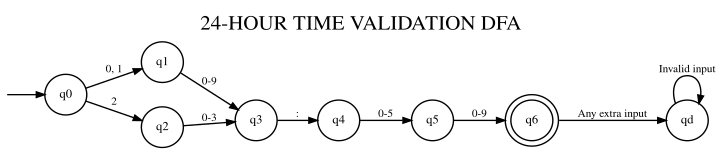

In [2]:
# =====================================================
# TIME FORMAT VALIDATION - DFA STATE DIAGRAM
# =====================================================

from graphviz import Digraph

dot = Digraph('Time_DFA')

# Compact diagram settings
dot.attr(
    rankdir='LR',
    size='10,2.5!',
    ratio='compress',
    nodesep='0.25',
    ranksep='0.35',
    margin='0.1',
    label='24-HOUR TIME VALIDATION DFA',
    labelloc='t',
    fontsize='15'
)

dot.attr(
    'node',
    shape='circle',
    width='0.42',
    height='0.42',
    fixedsize='true',
    fontsize='9'
)

dot.attr(
    'edge',
    fontsize='8',
    arrowsize='0.6'
)

# STEP 1: Create DFA states

dot.node('start', label='', shape='none', width='0')

states = ['q0', 'q1', 'q2', 'q3',
          'q4', 'q5', 'q6', 'qd']

for state in states:
    if state == 'q6':
        dot.node(state, shape='doublecircle')
    else:
        dot.node(state)

# STEP 2: Set initial state

dot.edge('start', 'q0')

# STEP 3: Add transitions

dot.edge('q0', 'q1', label='0, 1')
dot.edge('q0', 'q2', label='2')

dot.edge('q1', 'q3', label='0-9')
dot.edge('q2', 'q3', label='0-3')

dot.edge('q3', 'q4', label=':')

dot.edge('q4', 'q5', label='0-5')
dot.edge('q5', 'q6', label='0-9')

# STEP 4: Add dead state transitions

dot.edge('q6', 'qd', label='Any extra input')
dot.edge('qd', 'qd', label='Invalid input')

# STEP 5: Display diagram

dot